# London Air Quality Exploratory Data Analysis

**Exploratory analysis of 43,800 hourly air-quality records from monitoring site CT3 during 2017**

**Date:** October 7, 2026

## 1. Business context

Air quality is an important environmental concern in urban areas. Reviewing historical measurements can help identify how recorded pollutant values vary over time and where data-quality limitations may affect interpretation.

## 2. Project objective

This project explores hourly air-quality measurements to:
- assess the structure and completeness of the dataset;
- summarize the distribution of each recorded pollutant;
- examine monthly average values; and
- identify limitations that should be considered before drawing conclusions.

The analysis is descriptive. It does not attempt to establish causes or relationships between pollutants.

## 3. Scope and limitations

- The dataset contains measurements from one monitoring site (`CT3`) over 2017, with five pollutant codes.
- Results describe this dataset and should not be generalized to all of London or to other years.
- Missing and extreme values are retained during the initial exploration rather than being automatically removed or replaced.

## 4. Dataset source

The file used for this project is `LaqnData.csv`, obtained by the project author from *Hands-On Data Preprocessing in Python*. The analysis below is based on the provided file; the source documentation should be consulted before interpreting measurement units, status codes, or unusual readings.

## 5. Load the data

The CSV file is located in the `data` folder of this project, which makes the analysis easier to reproduce on another computer.

In [1]:
# Import the libraries used to load, inspect, summarize, and visualize the data.
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV file into a pandas DataFrame for analysis.
df = pd.read_csv("../data/S2_LaqnData.csv")

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

Rows: 43800 | Columns: 6


### Data dictionary

| Column | Description | Type |
|---|---|---|
| `Site` | Monitoring site code (`CT3`) | Categorical |
| `Species` | Pollutant code (`NO`, `NO2`, `NOX`, `PM10`, `PM2.5`) | Categorical |
| `ReadingDateTime` | Date and hour of the measurement (day/month/year hour:minute) | Datetime (stored as text) |
| `Value` | Recorded measurement; some values are missing | Numeric |
| `Units` | Unit label of the measurement; labels differ across pollutants (for example, `ug m-3`, `ug/m3` and `ug m-3 as NO2`) | Categorical |
| `Provisional or Ratified` | Record status; every record in this file has the status `R` | Categorical |

## 6. Inspect the dataset

The first rows help confirm that the file loaded correctly and show the available fields. The data types and non-null counts provide an initial view of the dataset's structure and completeness.

In [2]:
# Preview a few records to check the column names and the format of the values.
df.head()

,Site,Species,ReadingDateTime,Value,Units,Provisional or Ratified
0,CT3,NO,01/01/2017 00:00,3.5,ug m-3,R
1,CT3,NO,01/01/2017 01:00,3.6,ug m-3,R
2,CT3,NO,01/01/2017 02:00,2.2,ug m-3,R
3,CT3,NO,01/01/2017 03:00,2.1,ug m-3,R
4,CT3,NO,01/01/2017 04:00,3.3,ug m-3,R


In [3]:
# Review data types and non-null counts before choosing any transformations.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Site                     43800 non-null  str    
 1   Species                  43800 non-null  str    
 2   ReadingDateTime          43800 non-null  str    
 3   Value                    40570 non-null  float64
 4   Units                    43800 non-null  str    
 5   Provisional or Ratified  43800 non-null  str    
dtypes: float64(1), str(5)
memory usage: 2.0 MB


### Initial structure findings

The dataset contains 43,800 records and six columns: 8,760 hourly records for each of five pollutant codes. Only `Value` has missing entries (40,570 of 43,800 records are available), so any later treatment should focus on that column. `ReadingDateTime` is stored as text and is converted to a datetime type in the next section. Missing values are kept at this stage rather than removed or imputed.

## 7. Prepare the datetime column

`ReadingDateTime` is initially stored as text. Converting it to a datetime type allows the analysis to group observations by month and inspect the time range reliably.

In [4]:
# Convert the timestamp text into a datetime value so time-based analysis works correctly.
df["ReadingDateTime"] = pd.to_datetime(
    df["ReadingDateTime"],
    format="%d/%m/%Y %H:%M"
)

# Confirm the first and last timestamps represented in the dataset.
print(f"Start date: {df['ReadingDateTime'].min()}")
print(f"End date:   {df['ReadingDateTime'].max()}")

Start date: 2017-01-01 00:00:00
End date:   2017-12-31 23:00:00


## 8. Review data coverage and metadata

Before interpreting the measurements, check which sites, pollutant codes, units, and record-status labels are present. This matters because measurements with different unit labels should not be treated as directly interchangeable.

In [5]:
# Count records for each pollutant code to see whether coverage is balanced across species.
df["Species"].value_counts().sort_index()

Species
NO       8760
NO2      8760
NOX      8760
PM10     8760
PM2.5    8760
Name: count, dtype: int64

In [6]:
# List the unit label associated with each pollutant code; do not normalize units without documentation.
df.groupby("Species")["Units"].unique()

Species
NO              [ug m-3]
NO2             [ug m-3]
NOX      [ug m-3 as NO2]
PM10             [ug/m3]
PM2.5           [ug m-3]
Name: Units, dtype: object

In [7]:
# Check how many monitoring sites and record-status labels are represented in the file.
print("Sites:", df["Site"].unique())
print("Record status:", df["Provisional or Ratified"].unique())

Sites: <StringArray>
['CT3']
Length: 1, dtype: str
Record status: <StringArray>
['R']
Length: 1, dtype: str


### Initial coverage findings

The dataset contains measurements of five air pollutants from one monitoring station, CT3, and every record has the same status label (`R`). Therefore, the analysis focuses on air quality at this specific location rather than representing all of London. The dataset also includes different unit labels, so the original values and units are kept to avoid incorrect comparisons between pollutants.

## 9. Assess missing values

Missing measurements can affect summary statistics and make some time periods less comparable than others. The next table reports the number and percentage of missing values for each pollutant. Missing values are not replaced with zero because an unrecorded measurement is not the same as a measured concentration of zero.

In [8]:
# Summarize the total number of records and the number of available measurements for each pollutant.
data_quality = df.groupby("Species")["Value"].agg(
    total_records="size",
    available_values="count"
)

# Calculate missing counts and percentages so completeness can be compared across pollutants.
data_quality["missing_values"] = (
    data_quality["total_records"] - data_quality["available_values"]
)
data_quality["missing_pct"] = (
    data_quality["missing_values"] / data_quality["total_records"] * 100
)

# Round the percentage for readability while retaining counts as whole numbers.
data_quality["missing_pct"] = data_quality["missing_pct"].round(2)
data_quality.sort_index()

,total_records,available_values,missing_values,missing_pct
Species,,,,
NO,8760,8660,100,1.14
NO2,8760,8660,100,1.14
NOX,8760,8660,100,1.14
PM10,8760,8657,103,1.18
PM2.5,8760,5933,2827,32.27


### Missing value findings

PM2.5 has substantially more missing measurements than the other pollutant codes: 2,827 of its 8,760 records (32.27%) are missing, against about 1.1% for each of the other four. This limits the strength of comparisons involving PM2.5. The missingness pattern is examined by month below to make those limitations more visible.

In [9]:
# Add a month number so missingness can be summarized consistently by pollutant and month.
df["Month"] = df["ReadingDateTime"].dt.month

# Calculate the percentage of missing measurements in each pollutant-month group.
monthly_missing_pct = (
    df["Value"].isna()
    .groupby([df["Species"], df["Month"]])
    .mean()
    .mul(100)
    .unstack("Month")
)

# Round percentages to one decimal place to make the table easier to scan.
monthly_missing_pct.round(1)

Month,1,2,3,4,5,6,7,8,9,10,11,12
Species,,,,,,,,,,,,
NO,0.4,0.1,0.3,6.4,3.9,0.0,0.1,0.1,0.3,0.3,1.8,0.0
NO2,0.4,0.1,0.3,6.4,3.9,0.0,0.1,0.1,0.3,0.3,1.8,0.0
NOX,0.4,0.1,0.3,6.4,3.9,0.0,0.1,0.1,0.3,0.3,1.8,0.0
PM10,1.2,0.0,0.3,3.2,0.4,0.0,0.3,0.3,2.8,5.2,0.1,0.3
PM2.5,25.0,0.0,5.4,24.3,1.1,4.9,0.5,73.1,100.0,100.0,50.7,0.8


### Monthly missing value findings

The PM2.5 gaps are concentrated in a few months: about 73% of its records are missing in August, all of them in September and October, and about 51% in November, with smaller gaps in January and April (about 25% each). The other pollutants have at most 6.4% missing in any month, so their monthly averages rest on nearly complete data. Monthly results for PM2.5 should therefore be read with caution, and months without data are left empty rather than filled.

## 10. Summarize pollutant distributions

Descriptive statistics help us understand the measurements for each pollutant. They show the average values, how much the measurements vary, and the minimum and maximum values. The `count` column shows how many measurements are available for each pollutant, excluding missing values (`NaN`).

In [10]:
# Compare counts, averages, medians, spread, and extremes for the available measurements.
descriptive_stats = df.groupby("Species")["Value"].describe()

# Round the results for presentation without changing the underlying data.
descriptive_stats.round(2)

,count,mean,std,min,25%,50%,75%,max
Species,,,,,,,,
NO,8660.0,15.05,26.68,-2.0,3.1,7.1,15.5,401.8
NO2,8660.0,38.01,18.58,2.8,23.8,35.3,49.9,120.2
NOX,8660.0,61.08,54.58,1.0,30.3,46.9,73.8,734.3
PM10,8657.0,22.55,15.34,-5.6,13.9,19.5,27.3,633.1
PM2.5,5933.0,15.00,13.56,-8.0,7.0,11.0,18.0,128.0


### Descriptive statistics findings

For all five pollutants the mean is higher than the median (for example, NOX has a mean of about 61 and a median of about 47), which is consistent with right-skewed distributions or the influence of high readings. NO, NOX and PM10 have maximum values far above their medians (401.8, 734.3 and 633.1, against medians of 7.1, 46.9 and 19.5), so these extremes can pull the averages upward and need to be validated before any conclusion relies on them. NO, PM10 and PM2.5 also have negative minimum values (-2.0, -5.6 and -8.0), whose meaning should be checked against the measurement documentation. PM2.5 is based on 5,933 of 8,760 expected hourly records. All of these values are kept in the data at this stage and flagged for later review.

## 11. Explore monthly average values

Monthly averages help reveal within-year patterns in the recorded measurements. Each pollutant is plotted in its own panel because the recorded scales and unit labels differ. This avoids suggesting that the vertical distance between different pollutant lines is directly comparable.

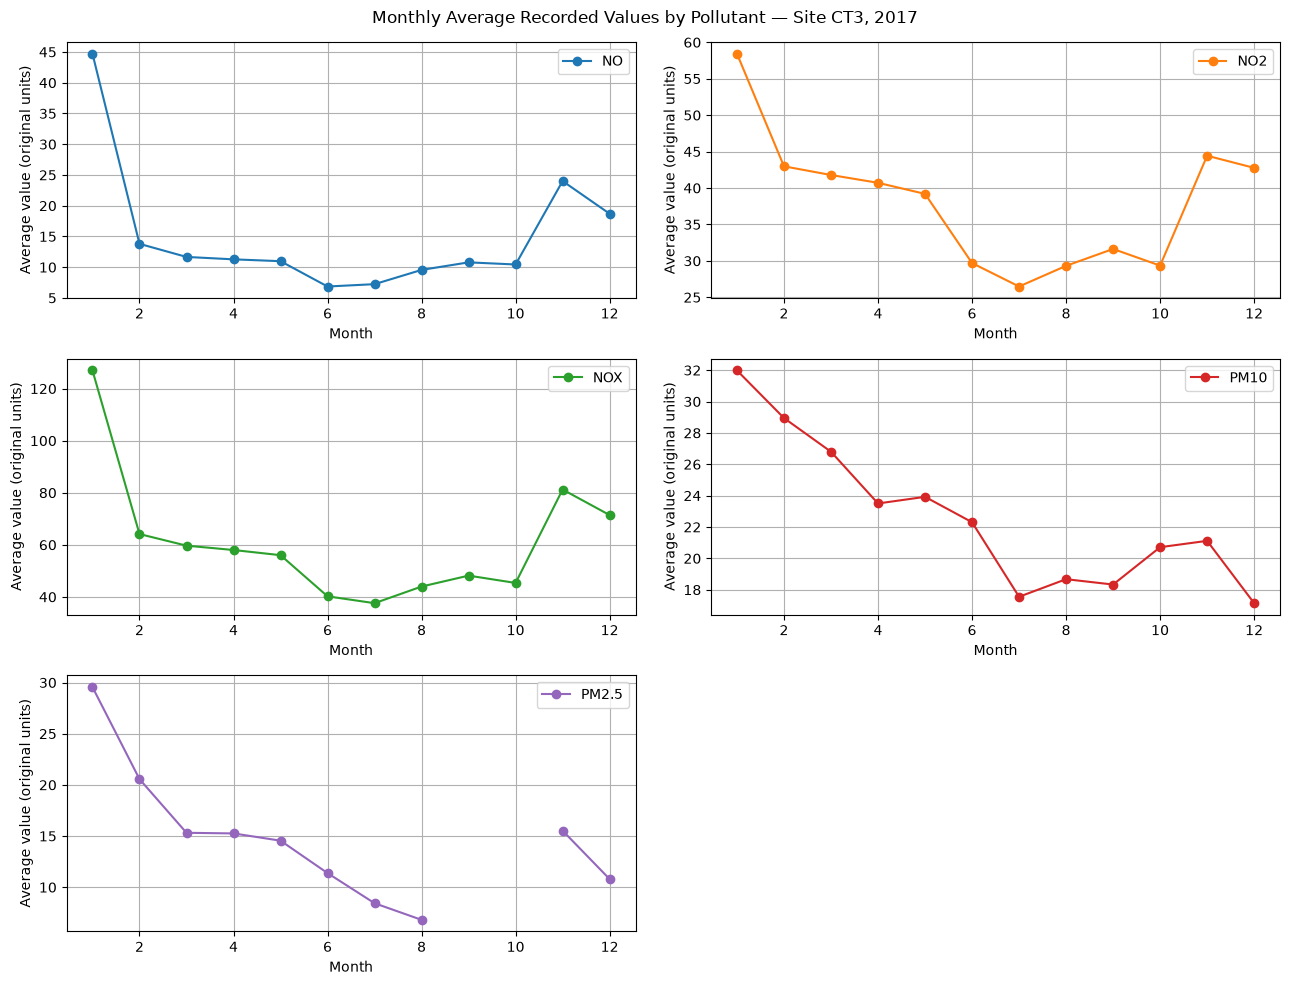

In [11]:
# Calculate the mean recorded value for each pollutant and month.
monthly_means = df.groupby(["Month", "Species"])["Value"].mean().unstack("Species")

# Plot each pollutant in a separate panel so its monthly pattern is easier to inspect.
axes = monthly_means.plot(
    subplots=True,
    layout=(3, 2),
    figsize=(13, 10),
    sharex=False,
    marker="o",
    grid=True,
    xlabel="Month",
    ylabel="Average value (original units)"
)

# Add a title and reserve space for it above the subplot panels.
plt.suptitle("Monthly Average Recorded Values by Pollutant — Site CT3, 2017")
plt.tight_layout()
plt.show()

### Monthly average findings

January has the highest monthly average for all five pollutants in this dataset. The three nitrogen pollutants (NO, NO2 and NOX) fall to their lowest values in June and July and rise again in November. PM10 declines more gradually and is lowest in July and December. PM2.5 declines until August, has no values in September and October, and is higher again in November before falling in December. These are descriptive patterns in one year of measurements, not proof of a recurring seasonal effect or evidence of what caused the changes.

The PM2.5 gap in September and October stays visible in the plot rather than being filled with zero or interpolated without a justified method.

## 12. Visualize the distributions

Histograms help us understand how the values of each pollutant are distributed. They show which values occur most often and whether the measurements are similar or vary widely. Each bar represents the number of measurements within a specific value range. Only available measurements are included, so missing values are not shown.

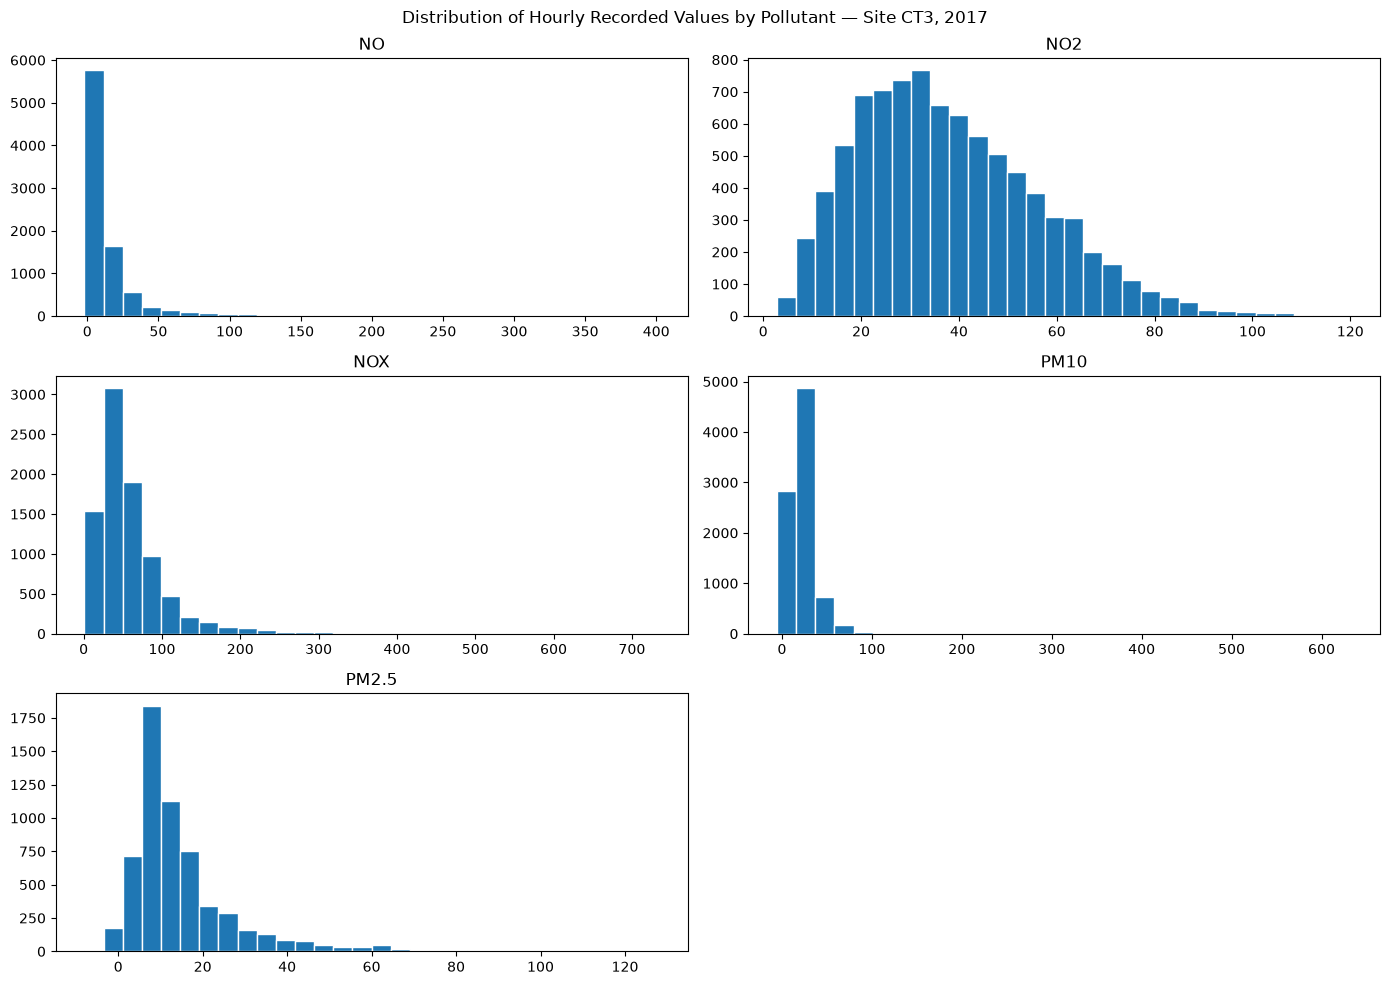

In [12]:
# Reshape the long-format dataset into one column per pollutant for side-by-side histograms.
# A pivot is useful here because each pollutant will receive its own histogram panel.
df_species_values = df.pivot(
    index="ReadingDateTime",
    columns="Species",
    values="Value"
)

# Draw one histogram per pollutant and use the column names as individual subplot titles.
axes = df_species_values.hist(
    bins=30,
    figsize=(14, 10),
    layout=(3, 2),
    grid=False,
    edgecolor="white"
)

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Distribution of Hourly Recorded Values by Pollutant — Site CT3, 2017")
plt.tight_layout()
plt.show()

### Distribution findings

NO, NOX, PM10 and PM2.5 are concentrated at low values with a long tail to the right. For NO and PM10, most hourly records fall in the first one or two bars, and the high maximum readings (about 400 for NO, 730 for NOX and 630 for PM10) stretch the horizontal axis so the main shape is hard to read. PM2.5 peaks at about 10, and its histogram includes the negative values. NO2 is the exception, with a more symmetric shape that peaks around 30 and extends to about 120. These shapes are consistent with the means being higher than the medians, but the histograms alone do not explain why high values occurred. The extreme values remain in the data and are flagged for validation.

## 13. Conclusions and next steps

### Key findings

- **Coverage:** the file covers site CT3 during 2017 (43,800 hourly records) and should not be treated as representative of every location in London.
- **Completeness:** PM2.5 is missing 32.27% of its records, against about 1.1% for the other pollutants, with no values in September and October.
- **Distributions:** all five pollutants have a mean above the median. NO, NOX, PM10 and PM2.5 are concentrated at low values with a long right tail, while NO2 is more symmetric.
- **Monthly variation:** January has the highest monthly mean for each pollutant. The pattern is descriptive and does not establish a cause or a recurring seasonal trend.

### Data-quality issues

- **Extreme values:** maximum readings far above the medians for NO (401.8), NOX (734.3) and PM10 (633.1).
- **Negative values:** present for NO, PM10 and PM2.5.
- **Unit labels:** they differ across pollutants (including `ug/m3` for PM10 and `ug m-3 as NO2` for NOX), so values should not be assumed to be directly comparable.

### Next steps

- Review the dataset documentation to confirm the meaning of unit labels and the record-status code.
- Investigate unusually high and negative measurements.
- Decide on a missing-data strategy only after understanding why readings are absent; do not automatically replace missing values with zero.
- If broader conclusions are required, compare multiple monitoring sites and multiple years.

### Final note

This notebook is an exploratory analysis, not a regulatory assessment of air quality or a causal study. Its conclusions are limited to the data available in the dataset.